# 第九轮：本轮仍未达到70%

目标仍要求同一完整2,588场至少判对1,812场、固定0.5阈值及合法赛前信息。
本表最高观察为 **1760/2,588 = 68.01%**（`history_linear_C0.03_alpha1`，2023最高观察准确率，未选中，loss更差），
距目标还差 **52** 场。这个事后观察不改变任何分支的开发期冻结选择。
本轮冻结探索候选最高为 **1709/2,588**。2023及2022升级门槛均已重复使用；
不能把任何观察称为独立最终测试或SOTA。2024–2025继续封存，goal保持进行中。

## 一张完整条件对比表

| 条件 / 比较角色 | 正确数 / 2,588 | Accuracy | Log loss ↓ | 距70%正确数 |
| --- | ---: | ---: | ---: | ---: |
| 原历史输入 / 旧基准：排名 logistic 原基准（`rank_reference`） | 1640 | 63.37% | 0.629796 | 172 |
| 原历史输入 / 旧基准：R4：保留的纯历史概率推荐（`previous_probability_recommendation`） | 1696 | 65.53% | 0.609407 | 116 |
| 原历史输入 / 旧基准：R5：冻结准确率探索组合（`previous_round5_exploration`） | 1715 | 66.27% | 0.609871 | 97 |
| 原历史输入 / 旧基准：整体 Elo 原基准（开发期选 K=32）（`raw_elo_k32_diff`） | 1640 | 63.37% | 0.639146 | 172 |
| 历史输入；训练期市场监督：R7：市场监督学生（`market_lambda1`） | 1712 | 66.15% | 0.604599 | 100 |
| 当前开盘价＋T−21历史修正；缺失回退R4：2023最高观察准确率，未选中，loss更差（`history_linear_C0.03_alpha1`） | 1760 | 68.01% | 0.596723 | 52 |
| 当前末盘价优先；缺失用开盘或R4回退：固定对照 / 既有模型；分支保留推荐（`raw_market`） | 1752 | 67.70% | 0.587691 | 60 |
| T−21纯历史；原始数据/表征适配：pooled开发期冻结探索（`matchup_shared`） | 1709 | 66.04% | 0.606459 | 103 |
| T−21纯历史；原始数据/表征适配：固定对照 / 既有参考；相同序列输入的池化对照（`sequence_mean`） | 1704 | 65.84% | 0.606122 | 108 |
| T−21纯历史；原始数据/表征适配：pooled开发期冻结探索（`sequence_gru`） | 1703 | 65.80% | 0.608496 | 109 |
| T−21纯历史；原始数据/表征适配：最低新观察loss，未选中（`sequence_mean_r4blend0.75`） | 1696 | 65.53% | 0.605994 | 116 |
| T−21纯历史；原始数据/表征适配：pooled开发期冻结探索；分支保留/采用（`realmlp_td_s_r4blend0.75`） | 1697 | 65.57% | 0.607936 | 115 |



此前原始末盘优先报价和68.01%的未选开盘修正使用更晚市场信息，单列作背景；不归入纯历史模型。
原R4推荐、R5冻结准确率探索及R7市场监督学生分别保留原有角色。
补充时间审计发现历史报价源有不同轮次共享时间戳，不能把其UTC字段当作经核实的实际完赛时间。
核验全部历史图边后，额外要求已纠正赛事日期也满足T−21不会删除任何已用边；原数值结果完全不变。
这是对时间证据的限定，不证明更短滞后可用。[来源限制与可复核计数](docs/research/round9_freshness_feasibility.md)

## 这次改变了什么，结果支持什么

- **风格对位：** 同一188项主效应上，比较无新增交互、21项共享反对称交互及63项场地偏差。
  已有字段能够恢复双方风格水平，所以这是交互结构变化，不是新增信息。
  完整匹配结果见[分支报告](results/round9/matchup/report_summary.md)。
- **赛事序列：** 每人最近16个不同历史日期组，先合并同日比赛，再在四年、T−21窗口内编码22项统计。
  原始GRU判对1703场，池化对照判对1704场；GRU相对池化的loss变化为
  +0.002374。池化也看到时间字段，固定shuffle也可能被学会逆转；
  这些控制限定解释为表示/容量/时间对齐的比较。[序列报告](results/round9/sequence/report_summary.md)
- **全量表格神经网络：** 两个配方均使用全部326旧字段和33,833训练目标。
  TD-S的三种子平均为1705场、loss0.608981，普通MLP为1706场、
  loss0.608949。这是包含激活、优化和标签平滑差异的配方比较，不是单一架构因素实验。
  每个种子仅由更早内层年份选择轮数，再重新训练完整外层样本。[神经网络报告](results/round9/neural/report_summary.md)

本轮总计**8种拟合结构/配方、15个固定混合**。两条神经路线各24个种子/外层或最终模型，
另各24次内层轮数选择；加上12次线性拟合，共108个优化阶段，不把这些当108个独立结构选择。
种子始终平均，不选最好种子。所有目标、零历史球员及技术统计缺失记录都按协议保留。

## 冻结规则与建议

| 分支 | 2022净正确数 / 2,528 | 准确率变化 | 预设流程决定 |
| --- | ---: | ---: | --- |
| matchup | +0 | +0.000pp | `retain_round4` |
| sequence | -4 | -0.158pp | `retain_round4` |
| neural | +13 | +0.514pp | `adopt_neural` |

早选2020–2021，2022要求准确率至少+0.5个百分点且loss恶化不超过0.005；pooled2020–2022选择在2023之前冻结。
分支保留/采用与pooled探索角色不同，表中未选的最低loss也不能事后升级。
继续保留各信息条件及原始排名/Elo基准；本轮是否值得进入最终比较，必须在打开最终年份之前固定。

## 核验和复跑

基础环境测试：298通过、8个可选Torch跳过、
97子测试通过。隔离Torch环境另有23项聚焦测试通过；
其中7项特征测试与基础环境重叠，不重复计数。
三个独立模型审计覆盖36列完整预测，另核验神经种子平均、保存的OOF权重、时间分割和预处理。
序列的原始来源审计独立重建55个目标中的1,518个token、2,747场不同历史比赛；没有假称所有token均由独立算法重建。
无原始记录恰好落在四年边界的真实例子，也没有Carpet token；这些边界以合成测试覆盖。

```bash
.venv/bin/python -m scripts.train_matchup_round9
.venv-foundation/bin/python -m scripts.train_sequence_round9 --device cpu
.venv-foundation/bin/python -m scripts.train_neural_round9
.venv/bin/python -m scripts.audit_matchup_round9
.venv-foundation/bin/python -m scripts.audit_sequence_source_round9
.venv-foundation/bin/python -m scripts.audit_sequence_round9
.venv-foundation/bin/python -m scripts.audit_neural_round9
.venv/bin/python -m scripts.report_round9
```

需先重建前序轮次的已审计输入；大型矩阵、序列归档及权重本地保存并可按命令复跑。
报告器仅核验保存概率并生成展示，不训练或重选。神经审计不重播训练梯度轨迹；TD-S内层probe scaler没有原样保存，
只能按已记录内层ID和源码确定性重建，无法与未保存对象逐项比对。完整范围及限制见各audit文件。

[全部结果](results/round9/overview_comparison.csv) · [研究协议](docs/research/round9_protocol.md) ·
[方法和反例](docs/research/round9_ideas.md) · [执行版notebook](round9.ipynb) · [HTML](round9.html)


,branch,model,role,correct,accuracy,mean_log_loss
0,prior,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,prior,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,prior,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
4,prior,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,prior,market_lambda1,R7：市场监督学生,1712,0.661515,0.604599
6,prior,history_linear_C0.03_alpha1,2023最高观察准确率，未选中，loss更差,1760,0.680062,0.596723
7,prior,raw_market,固定对照 / 既有模型；分支保留推荐,1752,0.676971,0.587691
10,matchup,matchup_shared,pooled开发期冻结探索,1709,0.660355,0.606459
19,sequence,sequence_mean,固定对照 / 既有参考；相同序列输入的池化对照,1704,0.658423,0.606122
20,sequence,sequence_gru,pooled开发期冻结探索,1703,0.658037,0.608496


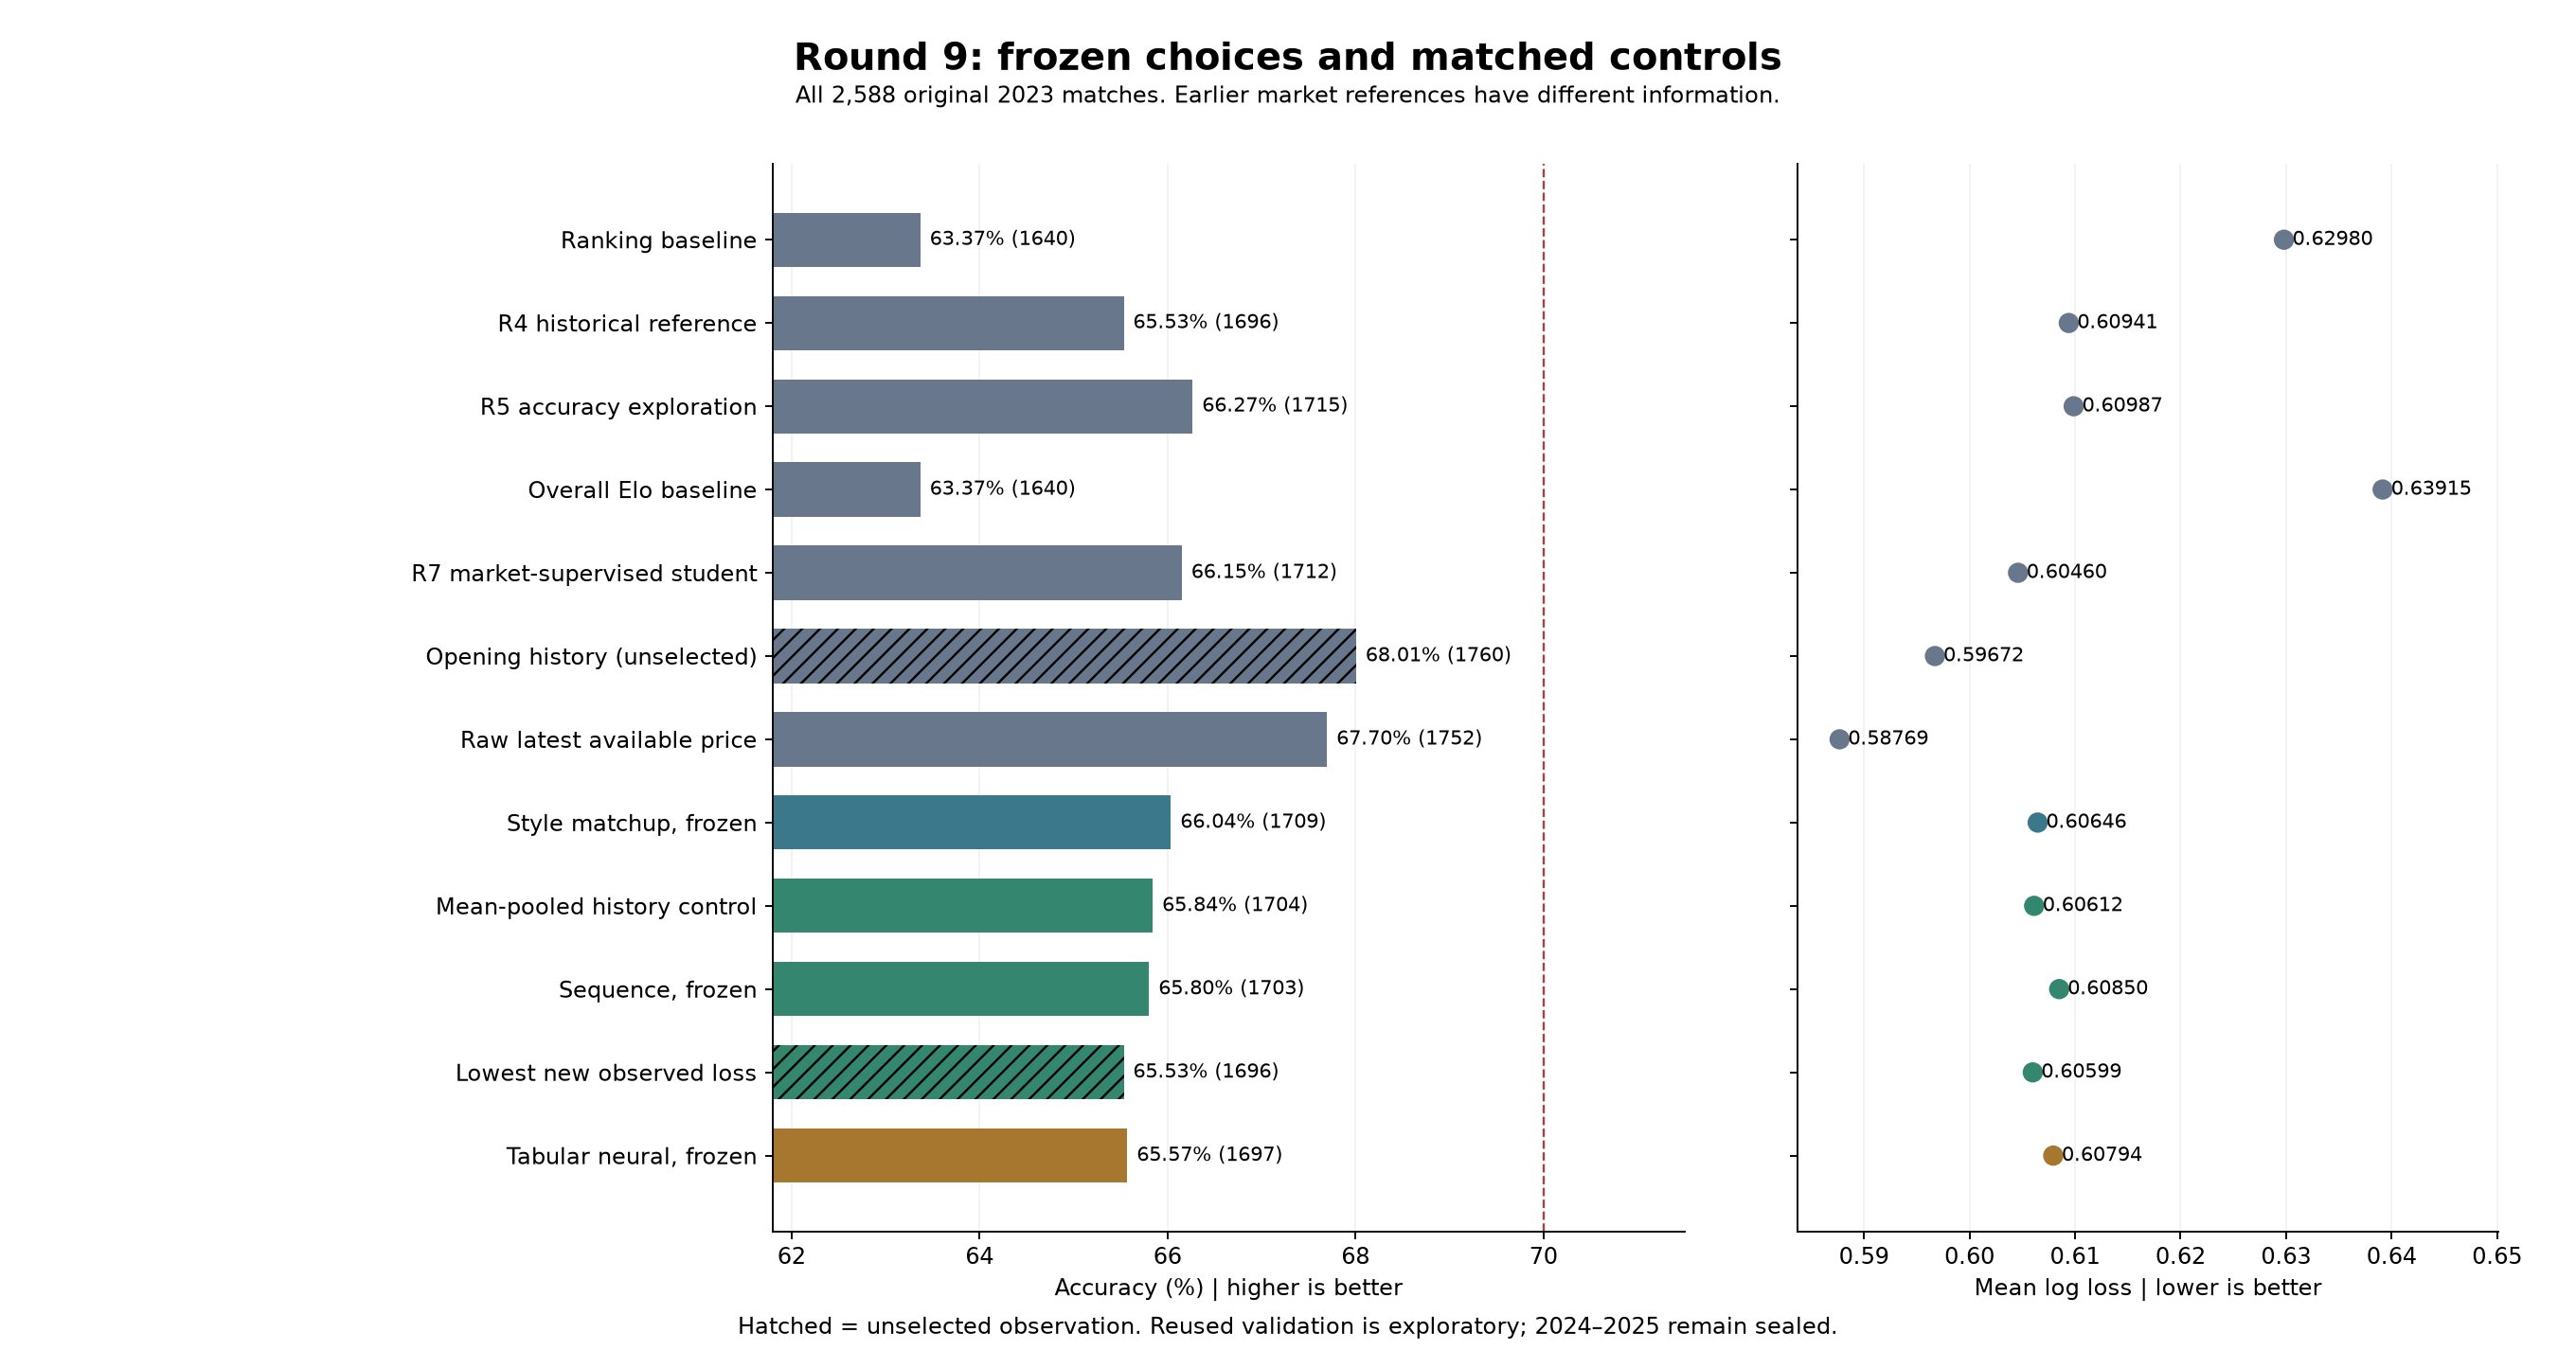

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
out=Path.cwd()/'results/round9'
table=pd.read_csv(out/'overview_comparison.csv')
assert table.matches.eq(2588).all()
display(table.loc[table.display,['branch','model','role','correct','accuracy','mean_log_loss']])
display(Image(filename=str(out/'round9_comparison.png')))

## 全部冻结比较

包含未选对照及重复的旧参考，未按2023重新选择。

In [2]:
with pd.option_context('display.max_rows',100,'display.max_colwidth',60):
    display(table[['branch','model','role','correct','accuracy','mean_log_loss']])

,branch,model,role,correct,accuracy,mean_log_loss
0,prior,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,prior,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,prior,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
3,prior,previous_round5_best_loss,R5：此前最低观察 loss 对照,1706,0.659196,0.606453
4,prior,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,prior,market_lambda1,R7：市场监督学生,1712,0.661515,0.604599
6,prior,history_linear_C0.03_alpha1,2023最高观察准确率，未选中，loss更差,1760,0.680062,0.596723
7,prior,raw_market,固定对照 / 既有模型；分支保留推荐,1752,0.676971,0.587691
8,matchup,previous_round5_exploration,固定对照 / 既有参考,1715,0.662674,0.609871
9,matchup,previous_round7_market_student,固定对照 / 既有参考,1712,0.661515,0.604599


## 匹配对照

不同阶段和信息条件分别保留。

In [3]:
for branch in ('matchup','sequence','neural'):
    print(branch)
    display(pd.read_csv(out/branch/'matched_controls.csv'))

matchup


,candidate,control,oof_accuracy_change,oof_loss_change,validation_accuracy_change,validation_loss_change
0,matchup_shared,matchup_no_new_interaction,0.000653,0.000070,0.001546,0.000074
1,matchup_surface,matchup_no_new_interaction,0.000163,0.000115,-0.000773,0.000062
2,matchup_surface,matchup_shared,-0.000489,0.000045,-0.002318,-0.000012


sequence


,candidate,control,oof_accuracy_change,oof_loss_change,validation_accuracy_change,validation_loss_change
0,sequence_gru,sequence_mean,0.000653,-0.000864,-0.000386,0.002374
1,sequence_gru,sequence_shuffled_gru,0.005220,-0.002097,0.004637,0.000627
2,sequence_shuffled_gru,sequence_mean,-0.004568,0.001233,-0.005023,0.001747


neural


,period,baseline,candidate,matches,accuracy_gain,log_loss_reduction
0,pooled,plain_mlp,realmlp_td_s,6130,0.001958,0.000457
1,2020,plain_mlp,realmlp_td_s,1214,0.011532,0.003394
2,2021,plain_mlp,realmlp_td_s,2388,-0.005444,0.001678
3,2022,plain_mlp,realmlp_td_s,2528,0.004351,-0.002106
4,2023,plain_mlp,realmlp_td_s,2588,-0.000386,-0.000032
